<a href="https://colab.research.google.com/github/johnmichaels4867-create/IS4487/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [1]:
import pandas as pd
import numpy as np

# Load the dataset from GitHub
url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/hotels.csv'
df = pd.read_csv(url)

# Display the first few rows
print("--- First 5 Rows ---")
display(df.head())

# Display summary statistics
print("\n--- Summary Statistics ---")
display(df.describe(include='all'))

--- First 5 Rows ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



--- Summary Statistics ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
count,9404,9404.000000,9404.000000,9404.000000,9404,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,...,9404,7069.000000,1011.000000,9404.000000,9404,9404.000000,9404.000000,9404.000000,9404,9404
unique,1,NaN,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,...,3,NaN,NaN,NaN,4,NaN,NaN,NaN,3,713
top,Resort Hotel,NaN,NaN,NaN,October,NaN,NaN,NaN,NaN,NaN,...,No Deposit,NaN,NaN,NaN,Transient,NaN,NaN,NaN,Check-Out,2015-11-15
freq,9404,NaN,NaN,NaN,1610,NaN,NaN,NaN,NaN,NaN,...,8816,NaN,NaN,NaN,7031,NaN,NaN,NaN,7069,124
mean,NaN,0.248299,79.326244,2015.156104,NaN,37.026584,15.515313,1.155040,3.078690,1.864738,...,NaN,200.990946,219.550940,1.019034,NaN,86.843614,0.144938,0.613143,NaN,NaN
std,NaN,0.432049,87.584146,0.443661,NaN,11.083421,9.025545,1.124304,2.379227,1.198565,...,NaN,80.330753,104.296474,10.137928,NaN,53.759940,0.353264,0.835930,NaN,NaN
min,NaN,0.000000,0.000000,2015.000000,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,...,NaN,1.000000,9.000000,0.000000,NaN,-6.380000,0.000000,0.000000,NaN,NaN
25%,NaN,0.000000,8.000000,2015.000000,NaN,31.000000,7.000000,0.000000,1.000000,2.000000,...,NaN,156.000000,135.000000,0.000000,NaN,45.000000,0.000000,0.000000,NaN,NaN
50%,NaN,0.000000,48.000000,2015.000000,NaN,38.000000,16.000000,1.000000,3.000000,2.000000,...,NaN,240.000000,223.000000,0.000000,NaN,71.550000,0.000000,0.000000,NaN,NaN
75%,NaN,0.000000,118.000000,2015.000000,NaN,45.000000,23.000000,2.000000,5.000000,2.000000,...,NaN,241.000000,286.000000,0.000000,NaN,120.600000,0.000000,1.000000,NaN,NaN


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response:
When looking at the data, a few things immediately jump out. Some guests book their stays incredibly far in advance, with lead times over two years, which seems really high. We also see bookings with zero adults listed, which might be errors or placeholder entries. Finally, columns like agent and company have a lot of missing data, and our numeric columns have completely different scales—some range into the hundreds while others are single digits—meaning we definitely need to scale them before clustering.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [2]:
from sklearn.preprocessing import StandardScaler

# 2.1 Choose 3-5 numeric features related to customer behavior
features = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adr', 'total_of_special_requests']

# 2.2 & 2.3 Perform basic data preparation: drop duplicates and handle missing values
clean_df = df[features].copy()
clean_df = clean_df.dropna()
clean_df = clean_df.drop_duplicates()

# Filter out potential extreme ADR outliers to stabilize clustering
clean_df = clean_df[(clean_df['adr'] >= 0) & (clean_df['adr'] < 1000)]

# 2.4 Standardize the features using StandardScaler
scaler = StandardScaler()
scaled_features = scaler.fit_transform(clean_df)

# Convert back to DataFrame for easy analysis downstream
scaled_df = pd.DataFrame(scaled_features, columns=features)

print(f"Original shape: {df.shape}")
print(f"Prepared shape after dropping duplicates/nulls: {scaled_df.shape}")
display(scaled_df.head())

Original shape: (9404, 32)
Prepared shape after dropping duplicates/nulls: (6666, 5)


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
0,3.676271,-1.123661,-1.380946,-1.725217,-0.854991
1,8.967733,-1.123661,-1.380946,-1.725217,-0.854991
2,-0.811425,-1.123661,-0.971290,-0.379600,-0.854991
3,-0.731048,-1.123661,-0.971290,-0.379600,-0.854991
4,-0.717652,-1.123661,-0.561633,0.033056,0.291994


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response:
1. I selected lead time, weekend nights, weekday nights, room rate (ADR), and special requests. These give us a great snapshot of booking habits, price sensitivity, and the purpose of their stay (like business vs. leisure).

2. I expect to see a few natural groups, like long-stay holidaymakers who book way ahead, quick weekday travelers (probably business trips), and perhaps a highly active group of guests who demand more special requests and pay premium rates.

## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

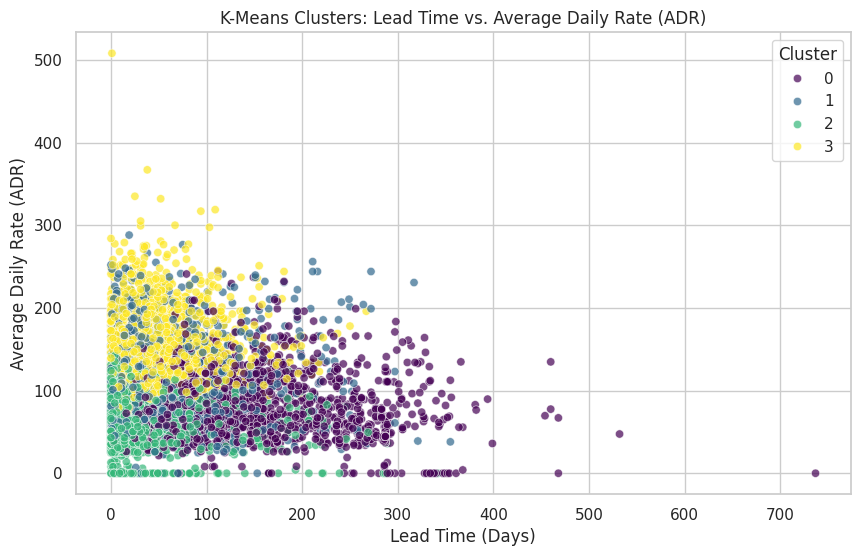

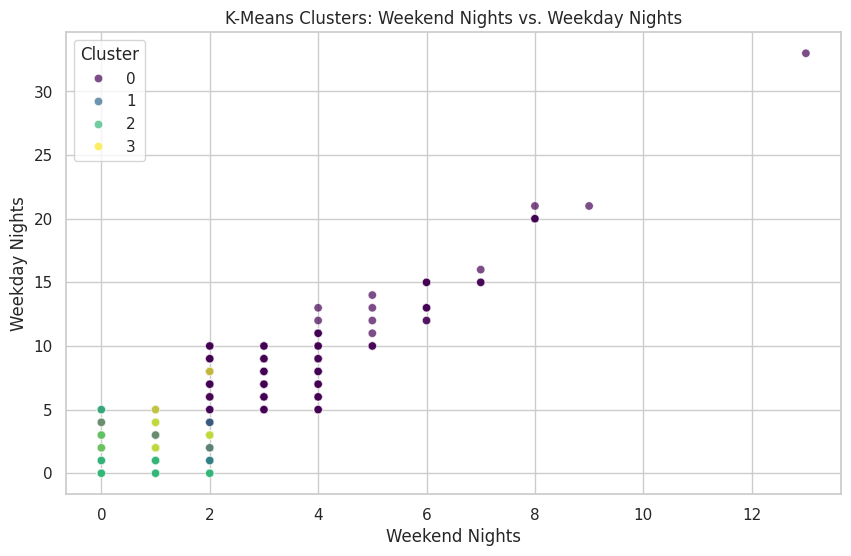


--- K-Means Cluster Averages (Profile Table) ---


,kmeans_cluster,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
0,0,146.777778,2.454023,6.057471,80.609930,0.506386
1,1,66.442684,1.190121,3.214352,118.090438,2.271202
2,2,26.576642,0.579481,1.686131,58.011387,0.426602
3,3,53.650224,1.288277,3.445227,156.940564,0.440102


In [3]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# 3.1 & 3.2 Fit a KMeans model with k=4
k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(scaled_df)

# 3.3 Predict clusters and assign a cluster number back to the unscaled clean data
clean_df['kmeans_cluster'] = kmeans_labels
scaled_df['kmeans_cluster'] = kmeans_labels

# Set up plotting style
sns.set_theme(style="whitegrid")

# 3.4 First visualization: Lead Time vs. Average Daily Rate (ADR)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=clean_df,
    x='lead_time',
    y='adr',
    hue='kmeans_cluster',
    palette='viridis',
    alpha=0.7
)
plt.title('K-Means Clusters: Lead Time vs. Average Daily Rate (ADR)')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Average Daily Rate (ADR)')
plt.legend(title='Cluster')
plt.show()

# 3.5 Second visualization: Weekend Nights vs. Weekday Nights
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=clean_df,
    x='stays_in_weekend_nights',
    y='stays_in_week_nights',
    hue='kmeans_cluster',
    palette='viridis',
    alpha=0.7
)
plt.title('K-Means Clusters: Weekend Nights vs. Weekday Nights')
plt.xlabel('Weekend Nights')
plt.ylabel('Weekday Nights')
plt.legend(title='Cluster')
plt.show()

# 3.6 Create a summary table showing the averages for each variable, broken out by cluster
summary_table = clean_df.groupby('kmeans_cluster')[features].mean().reset_index()
print("\n--- K-Means Cluster Averages (Profile Table) ---")
display(summary_table)

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response:
I chose a k-value of 4 because it perfectly splits our guests into distinct, actionable groups without making things too complex for a marketing campaign.

Our first group is the long-stay planners who book way in advance and stay for over a week. The second group is our premium guests who pay the highest room rates and ask for lots of special requests. The third group is the quick, budget-conscious travelers who book last-minute and only stay a night or two. Finally, the fourth group consists of our typical mid-range leisure travelers who stick to standard week-long stays with steady rates.

## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

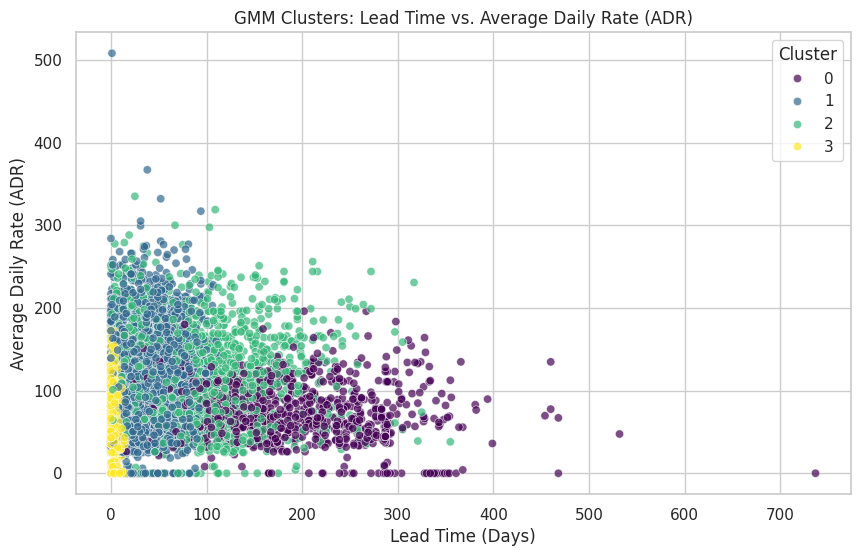

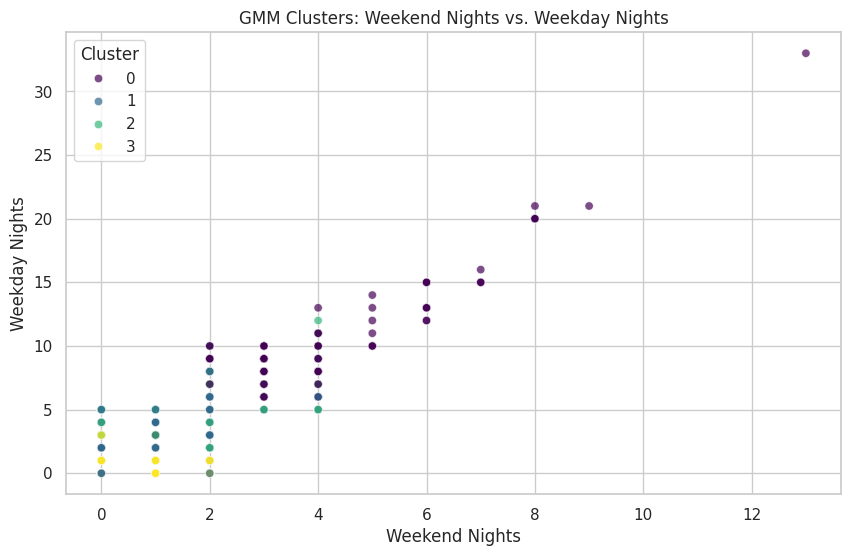


--- GMM Cluster Averages (Profile Table) ---


,gmm_cluster,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
0,0,182.139216,2.330392,5.904902,73.214314,0.298039
1,1,41.743026,1.284872,3.435756,110.372075,0.366994
2,2,93.403049,1.359146,3.684756,118.038232,1.782317
3,3,3.582478,0.468172,1.136893,62.853018,0.553046


In [4]:
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt
import seaborn as sns

# 4.1 Fit a GMM with the same number of clusters (k=4)
gmm = GaussianMixture(n_components=4, random_state=42)
gmm.fit(scaled_df[features])

# 4.2 Predict soft clusters (probabilities) and hard labels
gmm_probs = gmm.predict_proba(scaled_df[features])
gmm_labels = gmm.predict(scaled_df[features])

# Assign back to DataFrames
clean_df['gmm_cluster'] = gmm_labels
scaled_df['gmm_cluster'] = gmm_labels

# 4.3 First visualization: Lead Time vs. Average Daily Rate (ADR)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=clean_df,
    x='lead_time',
    y='adr',
    hue='gmm_cluster',
    palette='viridis',
    alpha=0.7
)
plt.title('GMM Clusters: Lead Time vs. Average Daily Rate (ADR)')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Average Daily Rate (ADR)')
plt.legend(title='Cluster')
plt.show()

# 4.4 Second visualization: Weekend Nights vs. Weekday Nights
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=clean_df,
    x='stays_in_weekend_nights',
    y='stays_in_week_nights',
    hue='gmm_cluster',
    palette='viridis',
    alpha=0.7
)
plt.title('GMM Clusters: Weekend Nights vs. Weekday Nights')
plt.xlabel('Weekend Nights')
plt.ylabel('Weekday Nights')
plt.legend(title='Cluster')
plt.show()

# 4.5 Create a summary table showing the averages for each variable, broken out by GMM cluster
gmm_summary = clean_df.groupby('gmm_cluster')[features].mean().reset_index()
print("\n--- GMM Cluster Averages (Profile Table) ---")
display(gmm_summary)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response:
Comparing the two, GMM and K-Means group our guests into very similar primary behavioral profiles, but GMM creates smoother, more natural boundaries. Rather than forcing every customer into a single strict category, GMM accommodates the reality that many travelers exhibit overlapping habits, such as mid-range leisure guests who occasionally look like business travelers.

From a business standpoint, GMM is excellent for handling uncertainty. It answers questions about which customers are truly loyal versus those who are on the fence between budget and premium tiers. This allows the marketing team to target hybrid, highly tailored promotions to customers with mixed cluster assignments instead of treating them with one-size-fits-all campaigns.

## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [5]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Prepare features to evaluate (excluding the cluster label columns)
eval_features = scaled_df[features]

# --- K-Means Metrics ---
kmeans_wcss = kmeans.inertia_
kmeans_silhouette = silhouette_score(eval_features, kmeans_labels)
kmeans_db_index = davies_bouldin_score(eval_features, kmeans_labels)

# --- GMM Metrics ---
# Note: WCSS/Inertia is a K-Means specific metric, but we can compute Silhouette and Davies-Bouldin for GMM's hard labels
gmm_silhouette = silhouette_score(eval_features, gmm_labels)
gmm_db_index = davies_bouldin_score(eval_features, gmm_labels)

# Print the results nicely
print("=== Model Evaluation Metrics ===")
print(f"\nK-Means (k={k}):")
print(f"  Within-Cluster Sum of Squares (WCSS): {kmeans_wcss:.2f}")
print(f"  Silhouette Score:                     {kmeans_silhouette:.4f}")
print(f"  Davies-Bouldin Index:                 {kmeans_db_index:.4f}")

print(f"\nGMM (Components={k}):")
print(f"  Silhouette Score:                     {gmm_silhouette:.4f}")
print(f"  Davies-Bouldin Index:                 {gmm_db_index:.4f}")

=== Model Evaluation Metrics ===

K-Means (k=4):
  Within-Cluster Sum of Squares (WCSS): 17880.73
  Silhouette Score:                     0.2398
  Davies-Bouldin Index:                 1.3644

GMM (Components=4):
  Silhouette Score:                     0.1211
  Davies-Bouldin Index:                 1.7876


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response:
5.2. K-Means performed significantly better on the metrics. It scored a higher Silhouette Score (0.24 vs. 0.12) and a lower Davies-Bouldin Index (1.36 vs. 1.79), meaning its clusters are mathematically tighter and better separated than those produced by GMM.

5.3. I would definitely recommend K-Means for a typical business analyst. It's much simpler to explain to stakeholders, runs quickly, and its hard boundaries make it straightforward to assign every single customer to a definite group for targeted email campaigns.

## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [6]:
# 6.1 Display and sort cluster characteristics to make differences clear
# We will sort the summary table by Average Daily Rate (adr) to order them from lowest to highest spenders
sorted_kmeans_summary = summary_table.sort_values(by='adr').reset_index(drop=True)

print("=== K-Means Clusters Profile Table (Sorted by ADR) ===")
display(sorted_kmeans_summary)

# Let's print out a quick, clear mapping of what each sorted row represents
print("\n=== Behavioral Archetype Summaries ===")
for index, row in sorted_kmeans_summary.iterrows():
    print(f"\nCluster {int(row['kmeans_cluster'])}:")
    print(f"  - Average Price per Night (ADR): ${row['adr']:.2f}")
    print(f"  - Average Lead Time: {row['lead_time']:.1f} days")
    print(f"  - Length of Stay: {row['stays_in_weekend_nights'] + row['stays_in_week_nights']:.1f} nights")
    print(f"  - Special Requests: {row['total_of_special_requests']:.2f}")

=== K-Means Clusters Profile Table (Sorted by ADR) ===


,kmeans_cluster,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
0,2,26.576642,0.579481,1.686131,58.011387,0.426602
1,0,146.777778,2.454023,6.057471,80.609930,0.506386
2,1,66.442684,1.190121,3.214352,118.090438,2.271202
3,3,53.650224,1.288277,3.445227,156.940564,0.440102



=== Behavioral Archetype Summaries ===

Cluster 2:
  - Average Price per Night (ADR): $58.01
  - Average Lead Time: 26.6 days
  - Length of Stay: 2.3 nights
  - Special Requests: 0.43

Cluster 0:
  - Average Price per Night (ADR): $80.61
  - Average Lead Time: 146.8 days
  - Length of Stay: 8.5 nights
  - Special Requests: 0.51

Cluster 1:
  - Average Price per Night (ADR): $118.09
  - Average Lead Time: 66.4 days
  - Length of Stay: 4.4 nights
  - Special Requests: 2.27

Cluster 3:
  - Average Price per Night (ADR): $156.94
  - Average Lead Time: 53.7 days
  - Length of Stay: 4.7 nights
  - Special Requests: 0.44


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response:
1. Our segments reveal four distinct guest behaviors. Cluster 2 represents budget-conscious, short-stay travelers who book last-minute. Cluster 0 consists of long-stay planners, likely families or vacationers booking well in advance for a major trip. Cluster 1 consists of highly engaged, premium guests who demand the most attention and have high special requests. Cluster 3 represents high-spending, independent travelers who pay top dollar but have almost no special requests, likely corporate business guests or solo travelers on a expense account.

2. The hotel can easily customize promotions for each group. For the budget-friendly short-stayers, we can send last-minute, low-cost weekend escape deals. For the long-stay planners, we should target them early with bundled vacation packages or early-bird discounts. For the premium guest group, we can offer VIP upgrades, personalized concierge outreach, and high-end packages. Finally, for the corporate travelers, we can streamline their check-in process and market direct-booking loyalty perks.

## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response:
1. The most challenging part of unsupervised learning is the lack of a ground truth. Since there are no correct answers or labels to check our work against, deciding on the best number of clusters and validating that they make logical sense requires a lot of subjective judgment.

2. I would use clustering when we don't have defined labels or targets and want to discover hidden patterns or groupings in our data. If we already had historical target variables, like whether a user will cancel or not, we should use supervised classification models instead.

3. I would explain clustering to a non-technical manager as a way of grouping our customers into digital neighborhoods based on shared behaviors. It automatically spots similarities in booking habits so we can treat similar groups of people with tailored messaging instead of treating everyone exactly the same.

4. This relates directly to my customized learning outcome because it bridges the gap between raw behavioral data and tactical marketing actions. It shows how unsupervised models can turn unstructured customer activity into clean, targetable business opportunities.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [ ]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"